# Notebook 02: Preprocessing, Baselines, and Neural Network

**Project:** AI-Based Personalized Learning and Student Performance Predictor (P38)

**Purpose of this notebook**
1. Load the dataset and recreate the agreed mastery target.
2. Split data into training, validation, and test sets.
3. Encode categorical features without leaking information from validation/test data.
4. Train two baselines and a small neural network.
5. Compare models using accuracy, macro-F1, per-class metrics, and confusion matrices.
6. Save the fitted models and reports for Notebook 03.

**Run the cells from top to bottom.** This notebook deliberately reloads the CSV and recreates the target so it does not depend on variables left over from Notebook 01.

> Important: the target labels are engineered from exam scores. The five categorical features are the only model inputs; exam scores and `average_score` must not be used as inputs because they define the target.

---
## 1. Imports and reproducibility

We import the libraries used for preprocessing, modelling, evaluation, and saving artifacts. A fixed random seed makes the data split and model initialization more reproducible; it does not guarantee identical results on every device.

In [1]:
import os
import random
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import tensorflow as tf
from tensorflow import keras

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print(f"Python packages imported successfully.")
print(f"scikit-learn version: {sklearn.__version__}")
print(f"TensorFlow version: {tf.__version__}")

I0000 00:00:1793248812.805712   26479 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793248813.035868   26479 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793248814.712403   26479 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Python packages imported successfully.
scikit-learn version: 1.9.1
TensorFlow version: 2.21.0


### Understand the important lines
- `train_test_split` creates separate data subsets for training, validation, and testing.
- `OneHotEncoder` converts categories into numerical columns that models can use.
- `SEED = 42` helps us repeat the same split and initialize the model consistently.

**Remember:** a test set is kept separate until final evaluation. We should not use its results to tune the model.

---
## 2. Find the project folder and load the dataset

The notebook may be opened with the working directory set to either the project root or the `notebooks/` folder. This cell checks both locations, then loads the CSV from `data/StudentsPerformance.csv`.

In [2]:
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "data" / "StudentsPerformance.csv").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "data" / "StudentsPerformance.csv").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Could not find data/StudentsPerformance.csv. "
        f"Current working directory: {CURRENT_DIR.resolve()}. "
        "Make sure the dataset is in the project's data/ folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "StudentsPerformance.csv"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print(f"Project root: {PROJECT_ROOT.resolve()}")
print(f"Dataset shape: {df.shape}")
display(df.head())

Project root: /home/waterball/Desktop/AI-Student-Performance-Predictor
Dataset shape: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Understand the important lines
- `Path.cwd()` tells us the notebook's current working directory.
- The two-path check makes the notebook work when launched from the project root or from `notebooks/`.
- `mkdir(..., exist_ok=True)` creates the output folders only if needed; it does not delete existing files.

---
## 3. Define features and recreate the target

The five categorical columns are model inputs. The target is created from the average of the three exam scores:

- **Low:** average below 50
- **Medium:** average from 50 to below 75
- **High:** average of 75 or above

These are project-defined categories, not labels supplied by the dataset. We intentionally exclude all exam scores from `X` to prevent target leakage.

In [3]:
CATEGORICAL_FEATURES = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
]
SCORE_COLUMNS = ["math score", "reading score", "writing score"]
CLASS_NAMES = ["Low", "Medium", "High"]
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
INDEX_TO_CLASS = {index: name for name, index in CLASS_TO_INDEX.items()}

expected_columns = CATEGORICAL_FEATURES + SCORE_COLUMNS
missing_columns = [column for column in expected_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing expected columns: {missing_columns}")

# Recalculate the target from the original exam scores.
df["average_score"] = df[SCORE_COLUMNS].mean(axis=1)
df["mastery_level"] = pd.cut(
    df["average_score"],
    bins=[-np.inf, 50, 75, np.inf],
    labels=CLASS_NAMES,
    right=False,
)

if df["mastery_level"].isna().any():
    raise ValueError("Some mastery labels are missing. Check the score columns.")

X = df[CATEGORICAL_FEATURES].copy()
y = df["mastery_level"].astype(str).copy()

print("Input features:")
print(CATEGORICAL_FEATURES)
print("\nTarget distribution:")
display(y.value_counts().reindex(CLASS_NAMES).rename("Number of students").to_frame())
print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)

Input features:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']

Target distribution:


,Number of students
mastery_level,
Low,103
Medium,573
High,324



Feature matrix shape: (1000, 5)
Target shape: (1000,)


### Understand the important lines
- `X` contains only the five categorical features.
- `y` contains the category we want to predict.
- The average score is used to **create** the target, but is deliberately not included in `X`.
- `pd.cut(..., right=False)` makes the intervals left-inclusive and right-exclusive: 50 belongs to Medium, and 75 belongs to High.

---
## 4. Create training, validation, and test sets

We use a **60% / 20% / 20%** split:

- Training set: fit the preprocessing and train models.
- Validation set: monitor the neural network and compare models before final evaluation.
- Test set: estimate final performance after modelling decisions are made.

Stratification tries to preserve the class proportions in each split.

In [4]:
# First reserve 20% for final testing.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
)

# Of the remaining 80%, reserve 25% for validation (0.25 * 0.80 = 0.20 overall).
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=SEED,
    stratify=y_train_val,
)

split_summary = pd.DataFrame({
    "Rows": [len(X_train), len(X_val), len(X_test)],
    "Percentage of dataset": [
        len(X_train) / len(df) * 100,
        len(X_val) / len(df) * 100,
        len(X_test) / len(df) * 100,
    ],
}, index=["Training", "Validation", "Test"])

display(split_summary.round(1))
print("\nMastery distribution by split (proportions):")
for split_name, labels in [("Training", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"\n{split_name}")
    display((labels.value_counts(normalize=True).reindex(CLASS_NAMES, fill_value=0) * 100).round(1).rename("Percentage"))

,Rows,Percentage of dataset
Training,600,60.0
Validation,200,20.0
Test,200,20.0



Mastery distribution by split (proportions):

Training


mastery_level
Low       10.3
Medium    57.3
High      32.3
Name: Percentage, dtype: float64


Validation


mastery_level
Low       10.5
Medium    57.0
High      32.5
Name: Percentage, dtype: float64


Test


mastery_level
Low       10.0
Medium    57.5
High      32.5
Name: Percentage, dtype: float64

### Understand the important lines
- Splitting before fitting the encoder prevents information from the validation/test sets influencing preprocessing.
- `test_size=0.20` reserves 20% for the final test.
- The second split uses 25% of the remaining 80%, giving 20% of the complete dataset for validation and 60% for training.
- `stratify=y` preserves class proportions as far as the sample sizes allow.

---
## 5. Encode the categorical features

Most machine-learning models need numerical inputs. **One-hot encoding** creates a separate 0/1 column for each category, rather than assigning arbitrary numeric rankings to categories.

We fit the encoder on `X_train` only. The same fitted encoder is then used to transform validation and test data.

In [5]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            CATEGORICAL_FEATURES,
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_val_encoded = preprocessor.transform(X_val)
X_test_encoded = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded validation shape:", X_val_encoded.shape)
print("Encoded test shape:", X_test_encoded.shape)
print(f"Number of encoded features: {len(feature_names)}")
display(pd.DataFrame(X_train_encoded, columns=feature_names).head())

Encoded training shape: (600, 17)
Encoded validation shape: (200, 17)
Encoded test shape: (200, 17)
Number of encoded features: 17


,gender_female,gender_male,race/ethnicity_group A,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_associate's degree,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_free/reduced,lunch_standard,test preparation course_completed,test preparation course_none
0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
4,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0


### Understand the important lines
- `fit_transform(X_train)` learns the categories from training data and encodes the training rows.
- `transform(...)` applies those same learned categories to validation and test rows.
- `handle_unknown="ignore"` prevents an error if a new category appears at prediction time.
- The small dataset is safe to represent as a dense array, so `sparse_output=False` is used here.

---
## 6. Train the two baseline models

Before using deep learning, we need simple reference points:

1. **Dummy Classifier:** always predicts the most common training class. This tells us how well a very simple strategy performs.
2. **Logistic Regression:** a conventional classification model that can learn relationships between the encoded features and the target.

A neural network is only meaningful to compare if we first measure these baselines.

In [6]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train_encoded, y_train)

logistic_model = LogisticRegression(max_iter=2000, random_state=SEED)
logistic_model.fit(X_train_encoded, y_train)


def calculate_metrics(y_true, y_pred):
    """Return accuracy and macro-F1 for a set of predictions."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(y_true, y_pred, labels=CLASS_NAMES, average="macro", zero_division=0),
    }

validation_predictions = {
    "Dummy Classifier": dummy_model.predict(X_val_encoded),
    "Logistic Regression": logistic_model.predict(X_val_encoded),
}

validation_results = pd.DataFrame([
    {"Model": name, **calculate_metrics(y_val, predictions)}
    for name, predictions in validation_predictions.items()
]).sort_values("Macro-F1", ascending=False).reset_index(drop=True)

display(validation_results.round(3))

,Model,Accuracy,Macro-F1
0,Logistic Regression,0.585,0.439
1,Dummy Classifier,0.570,0.242


### Understand the important lines
- The Dummy Classifier is a baseline, not a useful personalized predictor: it ignores the input features.
- Logistic Regression is our first feature-based model.
- **Accuracy** is the proportion of all predictions that are correct.
- **Macro-F1** calculates F1 separately for each class and then averages the three scores equally. This is useful when class sizes differ.

### Record your observations
After running the cell, add a short note here based on the **actual** validation scores. For example, identify which model has higher macro-F1 and whether either model improves meaningfully over the Dummy Classifier. Do not copy example numbers from elsewhere.

---
## 7. Build and train a small neural network

This project includes a deep-learning component, so we will train a small multilayer perceptron (MLP):

- Input layer: one unit per encoded feature.
- Dense layer: 64 units with ReLU activation.
- Dropout: 20% during training to help reduce overfitting.
- Dense layer: 32 units with ReLU activation.
- Output layer: three units with softmax, one for each mastery category.

We use Adam, sparse categorical cross-entropy, and early stopping on validation loss. Because the data is small and tabular, the neural network may or may not outperform Logistic Regression.

In [7]:
# Keras needs integer labels: Low=0, Medium=1, High=2.
y_train_encoded = y_train.map(CLASS_TO_INDEX).to_numpy(dtype=np.int32)
y_val_encoded = y_val.map(CLASS_TO_INDEX).to_numpy(dtype=np.int32)
y_test_encoded = y_test.map(CLASS_TO_INDEX).to_numpy(dtype=np.int32)

neural_model = keras.Sequential([
    keras.layers.Input(shape=(X_train_encoded.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(len(CLASS_NAMES), activation="softmax"),
])

neural_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

history = neural_model.fit(
    X_train_encoded,
    y_train_encoded,
    validation_data=(X_val_encoded, y_val_encoded),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1,
)

print(f"Training stopped after {len(history.history['loss'])} epoch(s).")

Epoch 1/100


E0000 00:00:1793248918.428651   26479 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5667 - loss: 0.9846 - val_accuracy: 0.5700 - val_loss: 0.9317
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5733 - loss: 0.9192 - val_accuracy: 0.5700 - val_loss: 0.9113
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5717 - loss: 0.8930 - val_accuracy: 0.5700 - val_loss: 0.8964
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5767 - loss: 0.8793 - val_accuracy: 0.5700 - val_loss: 0.8852
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5767 - loss: 0.8631 - val_accuracy: 0.5550 - val_loss: 0.8775
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5917 - loss: 0.8476 - val_accuracy: 0.5750 - val_loss: 0.8725
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5933 - loss: 0.8292 - val_accuracy: 0.5650 - val_loss: 0.8716
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6067 - loss: 0.8248 - val_accuracy: 0.5700 - val_loss: 0.8

### Understand the important lines
- The output layer has three probabilities; the values sum to approximately 1 for each student.
- `sparse_categorical_crossentropy` is appropriate because our targets are integer class IDs, not one-hot encoded target vectors.
- `EarlyStopping` monitors validation loss and restores weights from the best epoch if later epochs stop improving.
- Dropout randomly disables some units during training; it is inactive during normal inference.

---
## 8. Inspect the neural network learning curves

Training curves help us check whether the model is learning and whether validation performance starts to diverge from training performance.

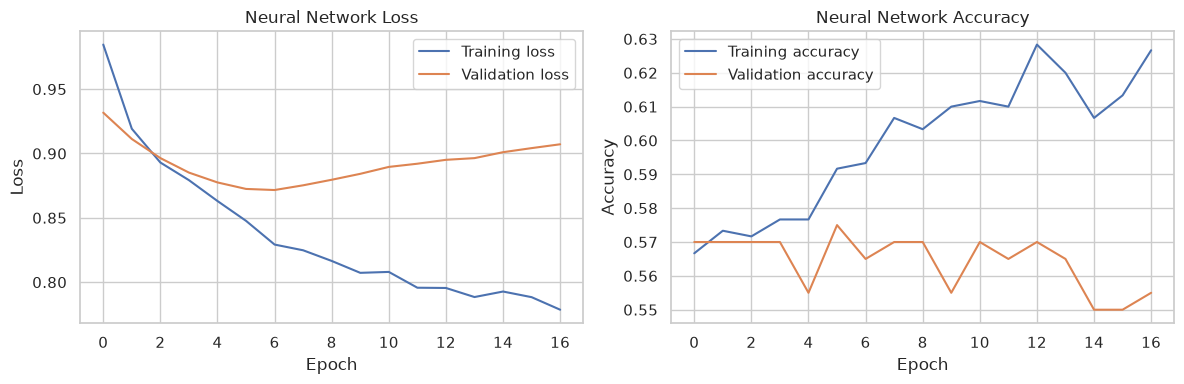

Saved training curves to: /home/waterball/Desktop/AI-Student-Performance-Predictor/reports/training_curves.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Neural Network Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Neural Network Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

fig.savefig(REPORTS_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
print(f"Saved training curves to: {REPORTS_DIR / 'training_curves.png'}")

### What to look for
- Training loss generally decreasing suggests the model is fitting the training data.
- Validation loss that keeps increasing while training loss decreases may indicate overfitting.
- The two curves do not need to match perfectly. A small dataset can produce noisy validation metrics.
- Do not decide that a model is good based on these curves alone; we will evaluate all models on the held-out test set.

---
## 9. Final evaluation on the held-out test set

We now evaluate all three models on the same test examples. We use accuracy and macro-F1 for a concise comparison, then inspect per-class metrics and confusion matrices. The test set should not be used to tune model settings.

In [9]:
# Predictions from the two baseline models.
test_predictions = {
    "Dummy Classifier": dummy_model.predict(X_test_encoded),
    "Logistic Regression": logistic_model.predict(X_test_encoded),
}

# Neural-network probabilities are converted back to the original category labels.
neural_test_probabilities = neural_model.predict(X_test_encoded, verbose=0)
neural_test_indices = np.argmax(neural_test_probabilities, axis=1)
test_predictions["Neural Network"] = np.array(
    [INDEX_TO_CLASS[int(index)] for index in neural_test_indices]
)

test_results = pd.DataFrame([
    {"Model": name, **calculate_metrics(y_test, predictions)}
    for name, predictions in test_predictions.items()
]).sort_values("Macro-F1", ascending=False).reset_index(drop=True)

display(test_results.round(3))
test_results.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)
print(f"Saved model comparison to: {REPORTS_DIR / 'model_comparison.csv'}")

,Model,Accuracy,Macro-F1
0,Logistic Regression,0.620,0.390
1,Neural Network,0.625,0.382
2,Dummy Classifier,0.575,0.243


Saved model comparison to: /home/waterball/Desktop/AI-Student-Performance-Predictor/reports/model_comparison.csv


### Interpret the comparison
- Compare models using both accuracy and macro-F1.
- The Dummy Classifier provides the minimum baseline to beat.
- If Logistic Regression outperforms the neural network, that is a valid result; a neural network is not automatically better, especially on a small tabular dataset.
- These measurements describe performance on this dataset and do not guarantee the same performance for other students or populations.

---
## 10. Per-class precision, recall, and F1-score

Overall metrics can hide weak performance on a smaller class. This section records precision, recall, and F1 separately for Low, Medium, and High. The rows are based on actual predictions from the held-out test set.

In [10]:
report_rows = []

for model_name, predictions in test_predictions.items():
    report = classification_report(
        y_test,
        predictions,
        labels=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    for class_name in CLASS_NAMES:
        report_rows.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1-score": report[class_name]["f1-score"],
            "Support": int(report[class_name]["support"]),
        })

per_class_results = pd.DataFrame(report_rows)
display(per_class_results.round(3))
per_class_results.to_csv(REPORTS_DIR / "test_classification_report.csv", index=False)
print(f"Saved per-class metrics to: {REPORTS_DIR / 'test_classification_report.csv'}")

,Model,Class,Precision,Recall,F1-score,Support
0,Dummy Classifier,Low,0.000,0.000,0.000,20
1,Dummy Classifier,Medium,0.575,1.000,0.730,115
2,Dummy Classifier,High,0.000,0.000,0.000,65
3,Logistic Regression,Low,0.000,0.000,0.000,20
4,Logistic Regression,Medium,0.618,0.887,0.729,115
5,Logistic Regression,High,0.629,0.338,0.440,65
6,Neural Network,Low,0.000,0.000,0.000,20
7,Neural Network,Medium,0.616,0.922,0.739,115
8,Neural Network,High,0.679,0.292,0.409,65


Saved per-class metrics to: /home/waterball/Desktop/AI-Student-Performance-Predictor/reports/test_classification_report.csv


### What do these metrics mean?
- **Precision:** among predictions made for a class, how many were correct?
- **Recall:** among the actual examples in a class, how many did the model identify?
- **F1-score:** the harmonic mean of precision and recall.
- **Support:** the number of actual test examples in that class.

Macro-F1 gives equal weight to each class, so it is useful when the classes are not evenly represented.

---
## 11. Confusion matrices

A confusion matrix shows correct and incorrect predictions by class. Rows represent actual categories and columns represent predicted categories.

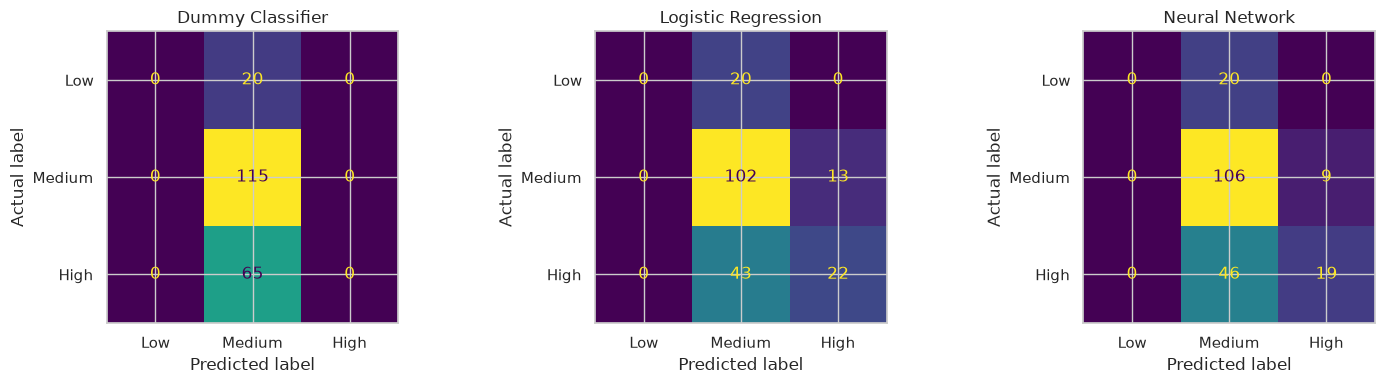

Saved confusion matrices to: /home/waterball/Desktop/AI-Student-Performance-Predictor/reports/confusion_matrices.png


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (model_name, predictions) in zip(axes, test_predictions.items()):
    matrix = confusion_matrix(y_test, predictions, labels=CLASS_NAMES)
    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=CLASS_NAMES,
    )
    display_matrix.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()
fig.savefig(REPORTS_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight")
print(f"Saved confusion matrices to: {REPORTS_DIR / 'confusion_matrices.png'}")

### How to read a confusion matrix
- The diagonal cells are correct predictions.
- Off-diagonal cells are mistakes.
- Check the Low row carefully because Low is the smallest class in this dataset.
- A model can have reasonable accuracy while missing many examples from a less common class.

---
## 12. A small interpretability exercise: Logistic Regression coefficients

Logistic Regression has coefficients associated with its encoded input features. We will visualize the largest coefficients by absolute magnitude for the **High** class. Treat these as learned model associations, not evidence that a feature causes a student's score to change.

,Feature,Coefficient
9,parental level of education_high school,-0.523
13,lunch_free/reduced,-0.519
16,test preparation course_none,-0.497
12,parental level of education_some high school,-0.450
2,race/ethnicity_group A,-0.311
0,gender_female,0.208
5,race/ethnicity_group D,0.300
6,race/ethnicity_group E,0.367
8,parental level of education_bachelor's degree,0.369
15,test preparation course_completed,0.498


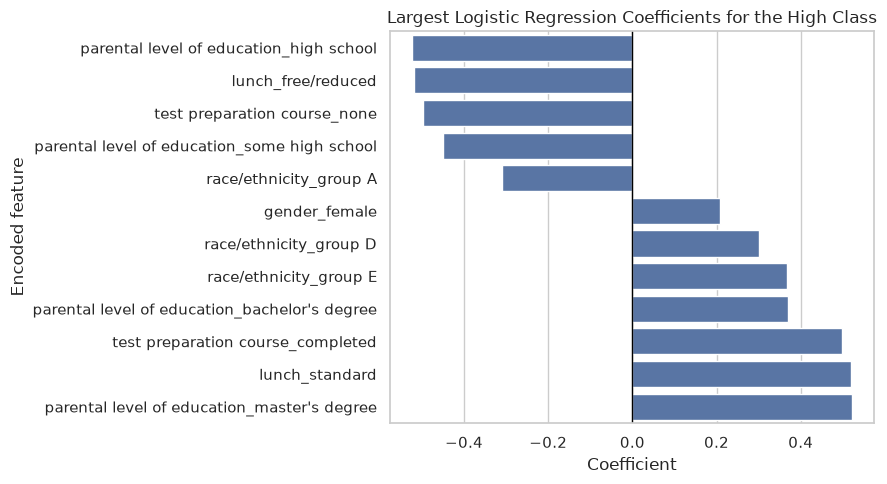

Saved coefficient plot to: /home/waterball/Desktop/AI-Student-Performance-Predictor/reports/logistic_regression_coefficients.png


In [12]:
# Find the coefficient row corresponding to the High class.
high_class_index = list(logistic_model.classes_).index("High")
high_coefficients = logistic_model.coef_[high_class_index]

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": high_coefficients,
})
coefficient_table["Absolute coefficient"] = coefficient_table["Coefficient"].abs()
coefficient_table = coefficient_table.sort_values(
    "Absolute coefficient", ascending=False
).head(12).sort_values("Coefficient")

display(coefficient_table.drop(columns="Absolute coefficient").round(3))

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=coefficient_table,
    x="Coefficient",
    y="Feature",
    ax=ax,
)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Largest Logistic Regression Coefficients for the High Class")
ax.set_xlabel("Coefficient")
ax.set_ylabel("Encoded feature")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "logistic_regression_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved coefficient plot to: {REPORTS_DIR / 'logistic_regression_coefficients.png'}")

### Important limitation
A positive coefficient contributes toward the model's High-class score relative to the model's other class scores, while a negative coefficient contributes in the opposite direction, all else equal. These coefficients depend on the model, coding, and data. They do **not** demonstrate causation, and demographic feature relationships should be interpreted carefully.

---
## 13. Save models and preprocessing artifacts

Notebook 03 needs the exact fitted encoder and trained models. We save:

- `student_mastery_model.keras`: the trained neural network.
- `preprocessor.joblib`: the encoder fitted on training data.
- `logistic_regression.joblib`: the Logistic Regression baseline.

The saved preprocessor must be used for future inputs; a new encoder fitted independently could produce columns in a different order.

In [13]:
neural_model_path = MODELS_DIR / "student_mastery_model.keras"
preprocessor_path = MODELS_DIR / "preprocessor.joblib"
logistic_model_path = MODELS_DIR / "logistic_regression.joblib"

neural_model.save(neural_model_path)
joblib.dump(preprocessor, preprocessor_path)
joblib.dump(logistic_model, logistic_model_path)

artifact_paths = [
    neural_model_path,
    preprocessor_path,
    logistic_model_path,
    REPORTS_DIR / "model_comparison.csv",
    REPORTS_DIR / "test_classification_report.csv",
    REPORTS_DIR / "training_curves.png",
    REPORTS_DIR / "confusion_matrices.png",
    REPORTS_DIR / "logistic_regression_coefficients.png",
]

artifact_status = pd.DataFrame({
    "Artifact": [str(path.relative_to(PROJECT_ROOT)) for path in artifact_paths],
    "Exists": [path.exists() for path in artifact_paths],
    "Size (bytes)": [path.stat().st_size if path.exists() else None for path in artifact_paths],
})
display(artifact_status)

if not artifact_status["Exists"].all():
    raise RuntimeError("One or more expected artifacts were not created. Check the output above.")

print("\nModels and reports saved successfully.")

,Artifact,Exists,Size (bytes)
0,models/student_mastery_model.keras,True,67797
1,models/preprocessor.joblib,True,2897
2,models/logistic_regression.joblib,True,1439
3,reports/model_comparison.csv,True,152
4,reports/test_classification_report.csv,True,572
5,reports/training_curves.png,True,116158
6,reports/confusion_matrices.png,True,82696
7,reports/logistic_regression_coefficients.png,True,89318



Models and reports saved successfully.


---
## 14. Checkpoint summary and revision notes

After every cell runs successfully, you should have:
- A 60% training, 20% validation, and 20% test split.
- A one-hot encoder fitted on training data only.
- Dummy Classifier, Logistic Regression, and neural-network models.
- Test metrics, per-class metrics, confusion matrices, training curves, and coefficient visualization.
- Saved models and preprocessing artifacts for Notebook 03.

### Viva questions

**Q1. Why do we split data into training, validation, and test sets?**

Training fits model parameters, validation helps monitor/select models, and test data provides a final evaluation on examples not used for those decisions.

**Q2. What is data leakage in this project?**

Using exam scores or average score as input features would leak information because those scores are used to create the mastery target. We use only the five categorical features as inputs.

**Q3. Why report macro-F1 as well as accuracy?**

Our Low, Medium, and High classes have different sizes. Accuracy can be dominated by the majority class, while macro-F1 gives each class equal weight.

**Q4. Must the neural network beat Logistic Regression?**

No. Model performance depends on the data. A simpler model may perform as well or better on a small tabular dataset; we report the measured results honestly.

### Before moving on

Run all cells from the top and check for errors. Keep your actual `model_comparison.csv` results; do not replace them with example numbers. Once you confirm that training, evaluation, and artifact saving all succeed, this is a major checkpoint and you should commit/push the new notebook and generated reports as appropriate.